
# Swiggy Data Analytics Project

## Project Overview

This project analyzes Swiggy order data to understand order trends, revenue distribution, restaurant performance, customer ratings, and price ranges.

The project uses SQL Server for data cleaning, transformation, and analysis. Python is used for data exploration and visualization.

## Objectives

- Analyze monthly order trends.
- Identify states contributing the highest revenue.
- Identify top-performing restaurants.
- Understand popular food categories.
- Explore customer rating distribution.
- Analyze orders across different price ranges.

## Tools and Technologies

- SQL Server
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

### Importing Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### loading files 

In [2]:
fact_orders = pd.read_csv(
    "swiggy_data/fact_swiggy_orders.csv"
)

dim_location = pd.read_csv(
    "swiggy_data/dim_location.csv"
)

print(fact_orders.head())
print(dim_location.head())

   order_id  date_id  Price_INR  Rating  Rating_Count  location_id  \
0         1      243      549.0     3.8            12          800   
1         2       32      439.0     4.7             6          800   
2         3      163      549.0     4.6            13          100   
3         4      230      439.0     3.5            19          100   
4         5      170      549.0     2.7             3          134   

   restaurant_id  category_id  dish_id  
0            598         4557    45102  
1            598         4557    46759  
2            598         4557    45102  
3            598         4557    46759  
4            598         4557    45102  
   location_id  State      City        Location
0            1  Assam  Guwahati        Amingaon
1            2  Assam  Guwahati           Azara
2            3  Assam  Guwahati         Beltola
3            4  Assam  Guwahati        BIRKUCHI
4            5  Assam  Guwahati  BishnuRavaPath


In [3]:
dim_category=pd.read_csv(f"swiggy_data/dim_category.csv")

In [4]:
dim_category

,category_id,Category
0,1,Tea Cakes
1,2,Bakery
2,3,No Deal Like McDeal
3,4,Puffs & Bakery Bites
4,5,Veerji Special Mojito
...,...,...
4725,4726,Chinese Combos
4726,4727,Single Meal
4727,4728,Garlic-breads
4728,4729,Chilli Sausages Hot Wings


In [5]:
dim_restaurant=pd.read_csv("swiggy_data/dim_restaurant.csv")

In [6]:
dim_date=pd.read_csv("swiggy_data/dim_date.csv")

In [7]:
dim_dish=pd.read_csv("swiggy_data/dim_dish.csv")

## Data Preprocessing

In [8]:
value_count=fact_orders['date_id'].value_counts()

In [9]:
Month_name={}
for i in value_count.index:
    Month_name[i]=dim_date[dim_date["date_id"]==i].Month_Name.values[0]

In [10]:
df_month = pd.DataFrame({
    "date_id": value_count.index,
    "count": value_count.values
})

df_month["Month"] = df_month["date_id"].map(Month_name)

df_month

,date_id,count,Month
0,195,1549,February
1,12,945,February
2,236,893,July
3,227,889,May
4,207,884,August
...,...,...,...
238,34,742,February
239,63,742,March
240,89,737,March
241,128,730,July


In [11]:
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

# Group by month and calculate total orders
monthly_orders = df_month.groupby("Month")["count"].sum()
monthly_orders = monthly_orders.reindex(month_order).dropna()

In [12]:
location_price=fact_orders.groupby("location_id")['Price_INR'].sum()

In [13]:
location=fact_orders['location_id'].unique()

In [14]:
state_name={}
for i in location:
    state_name[i]=dim_location[dim_location["location_id"]==i].State.values[0]

In [15]:
df_location = pd.DataFrame({
    "location_id": fact_orders.groupby("location_id")['Price_INR'].sum().index,
    "price": fact_orders.groupby("location_id")['Price_INR'].sum().values
})

df_location["state"] = df_location["location_id"].map(state_name)

df_location

,location_id,price,state
0,1,20838.00,Assam
1,2,139602.00,Assam
2,3,135802.50,Assam
3,4,8769.00,Assam
4,5,22000.00,Assam
...,...,...,...
956,957,13192.00,West Bengal
957,958,17441.69,West Bengal
958,959,14830.14,West Bengal
959,960,32453.00,West Bengal


In [16]:
top_10=df_location.groupby("state")['price'].sum().sort_values(ascending=False).head(10)

In [17]:
top_restaurant=fact_orders["restaurant_id"].unique()

In [18]:
restaurant_name={}
for i in top_restaurant:
    restaurant_name[i]=dim_restaurant[dim_restaurant["restaurant_id"]==i].Restaurant_Name.values[0]

In [19]:
df_restaurant= pd.DataFrame({
    "restaurant_id": fact_orders.groupby("restaurant_id")['Price_INR'].sum().index,
    "price": fact_orders.groupby("restaurant_id")['Price_INR'].sum().values
})

df_restaurant["Restaurant_Name"] = df_restaurant["restaurant_id"].map(restaurant_name)

df_restaurant

,restaurant_id,price,Restaurant_Name
0,1,22932.0,Mr. Pizza
1,2,31987.0,Khana Khazana (Shankar Nagar)
2,3,17870.0,The Grill Republic
3,4,10166.0,Hot Stuff Fast Food
4,5,54361.0,Bombay Mishthan Bhandar (Bmb) - Durapura
...,...,...,...
979,980,32727.0,Cake Plaza
980,981,190604.0,The Biryani Life
981,982,27636.0,Awadhi
982,983,12925.0,Green Chilly


In [20]:
top_restaurant=df_restaurant.groupby("Restaurant_Name")['price'].sum().sort_values(ascending=False).head(10)

In [21]:
category_id=fact_orders['category_id'].value_counts()

In [22]:
category_name={}
for i in category_id.index:
    category_name[i]=dim_category[dim_category["category_id"]==i].Category.values[0]

In [23]:
df_category = pd.DataFrame({
    "category_id": category_id.index,
    "count": category_id.values
})

df_category["Category"] = df_category["category_id"].map(category_name)

df_category

,category_id,count,Category
0,3844,24097,Recommended
1,3741,3582,Desserts
2,206,2983,Main Course
3,1130,2682,Beverages
4,3992,2538,BURGERS
...,...,...,...
4725,2951,1,Parotta Varieties
4726,1374,1,Oriental Staples Veg
4727,1165,1,Puja Specials
4728,3243,1,South indian curry items (kulambu)


In [24]:
most_order_category=df_category.head(10)

In [25]:
bins = [-float("inf"), 99.99, 199.99, 299.99, 499.99, float("inf")]
labels = [
    "Under 100",
    "100 - 199",
    "200 - 299",
    "300 - 499",
    "500+"
]
fact_orders["Price_Range"] = pd.cut(
    fact_orders["Price_INR"],
    bins=bins,
    labels=labels,
    include_lowest=True
)
price_range_orders = (
    fact_orders["Price_Range"]
    .value_counts()
    .reindex(labels, fill_value=0)
)

### Bivariant Analysis 

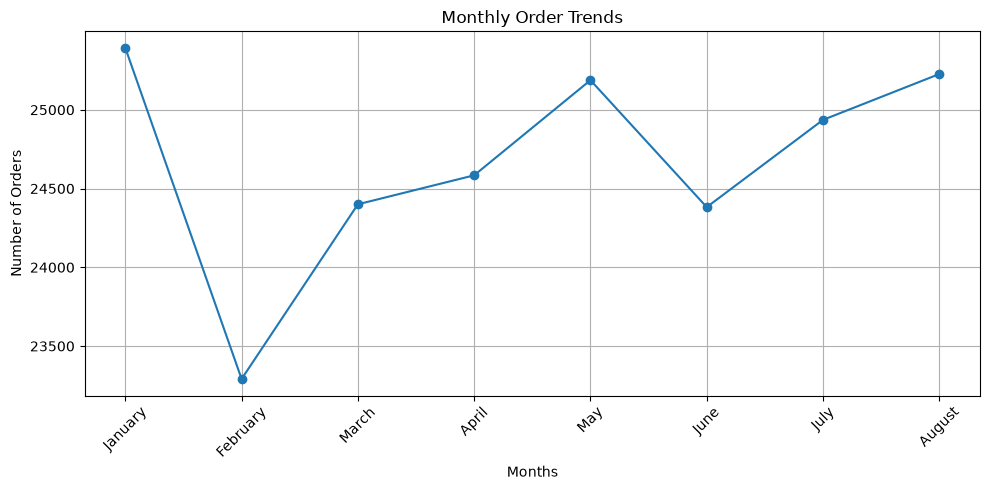

In [26]:
plt.figure(figsize=(10, 5))
plt.plot(monthly_orders.index, monthly_orders.values, marker="o")

plt.xlabel("Months")
plt.ylabel("Number of Orders")
plt.title("Monthly Order Trends")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

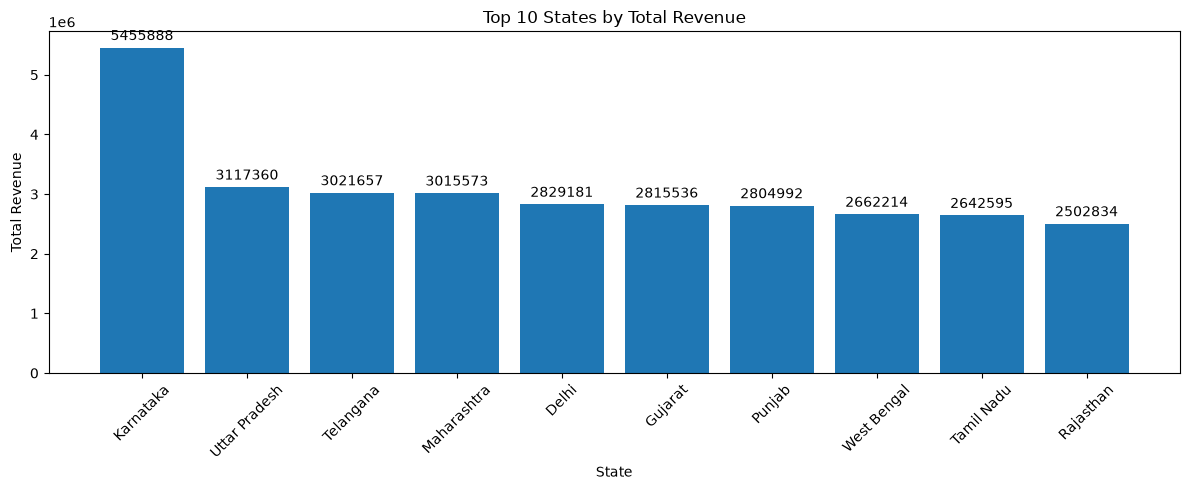

In [27]:
plt.figure(figsize=(12,5))
bars = plt.bar(top_10.index, top_10.values)
plt.bar_label(bars, fmt='%.0f', padding=3)
plt.xlabel('State')
plt.ylabel('Total Revenue')
plt.title('Top 10 States by Total Revenue')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

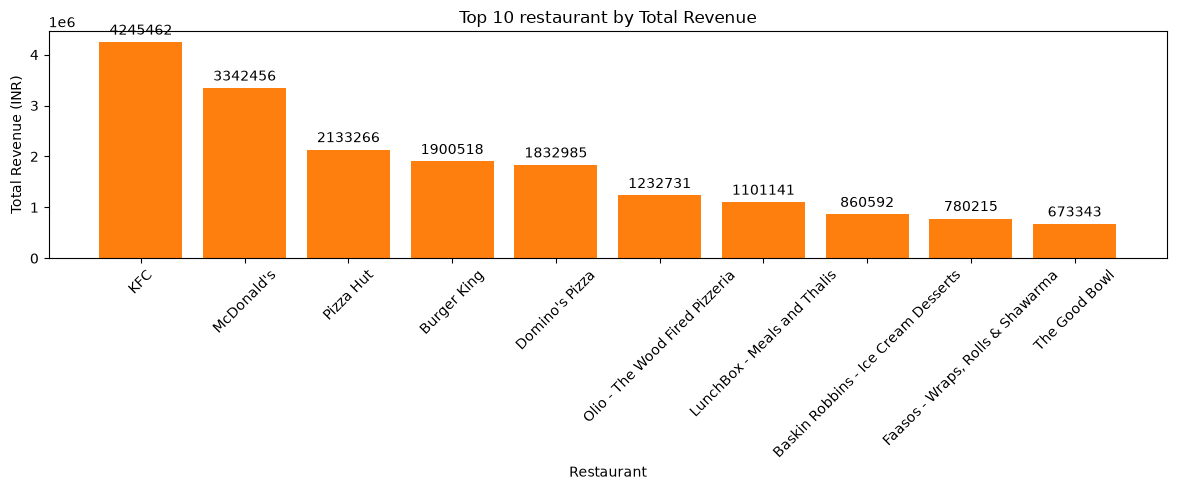

In [28]:
plt.figure(figsize=(12,5))
plt.bar(top_restaurant.index,top_restaurant.values)
bars = plt.bar(top_restaurant.index,top_restaurant.values)
plt.bar_label(bars, fmt='%.0f', padding=3)
plt.xlabel('Restaurant')
plt.ylabel('Total Revenue (INR)')
plt.title('Top 10 restaurant by Total Revenue')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

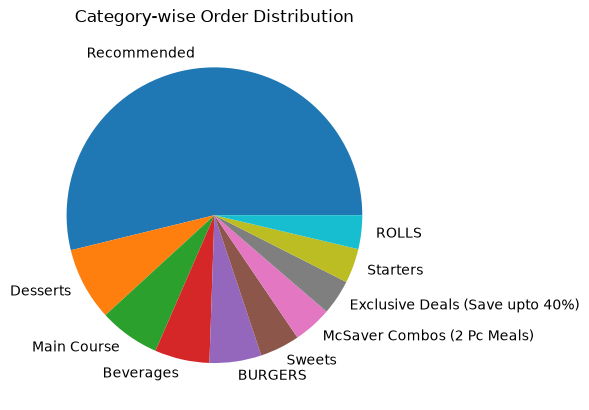

In [29]:
plt.pie(most_order_category['count'], labels=most_order_category['Category'])
plt.title("Category-wise Order Distribution")
plt.show()

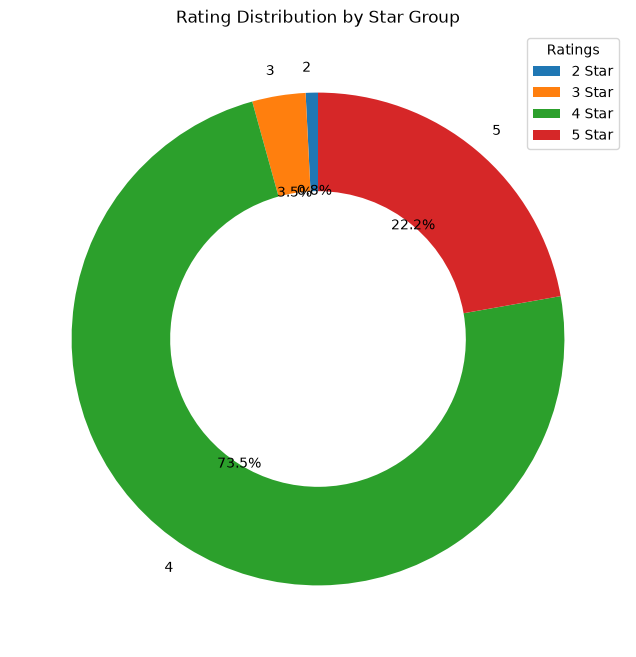

In [30]:
rating_counts = fact_orders["Rating"].round().astype("Int64").value_counts().sort_index()

plt.figure(figsize=(8, 8))

plt.pie(
    rating_counts,
    labels=rating_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4}
)

plt.title("Rating Distribution by Star Group")
plt.legend(
    title="Ratings",
    labels=[f"{rating} Star" for rating in rating_counts.index],
    loc="best"
)

plt.show()

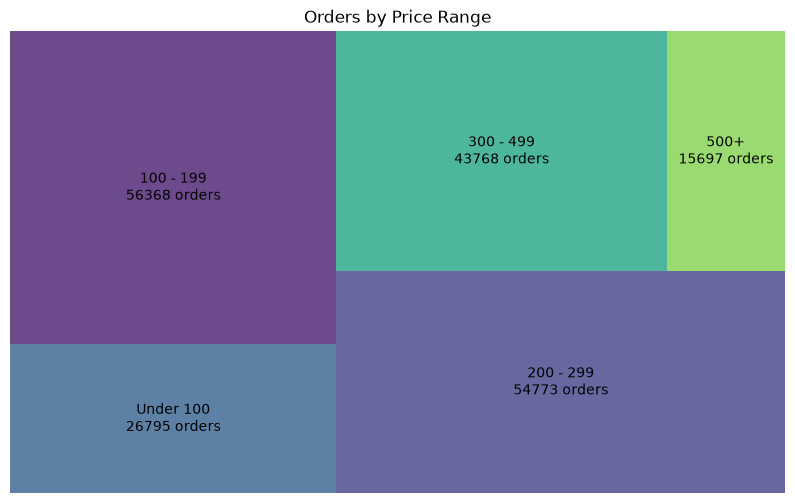

In [31]:
import squarify

plt.figure(figsize=(10, 6))

squarify.plot(
    sizes=price_range_orders.values,
    label=[
        f"{label}\n{count} orders"
        for label, count in zip(
            price_range_orders.index,
            price_range_orders.values
        )
    ],
    alpha=0.8
)

plt.title("Orders by Price Range")
plt.axis("off")
plt.show()


## Conclusion

This project demonstrates how SQL Server and Python can be used together for data analytics.

SQL Server was used to organize the dataset into a Star Schema and perform business-oriented queries. Python was used to analyze the results and create visualizations.

The analysis explored revenue by state, restaurant performance, category-wise orders, monthly order trends, customer ratings, and price-range distribution.

These findings can help support a better understanding of order patterns and business performance in the Swiggy dataset.
